# Daraja Connect: mentor recommender walkthrough

This notebook walks through the **content-based mentor recommender** for Kenya Airways Pride Centre alumni (mentees) and current or former Kenya Airways employees (mentors).

**What it is:** a content-based recommender. It compares mentee and mentor profiles using TF-IDF text similarity, skill-tag similarity and a specialisation match, then combines the three with weights. It is **not** a trained machine-learning model. The only tuned settings are the block weights and the missing-data policy, chosen on a validation split.

**About the data:** profiles and relevance labels are **synthetic**. The results show that the pipeline works and how the methods compare *under the generator's assumptions*. They are not evidence that the matches suit real people. That needs expert or participant ratings (section 6).

Run the pipeline first (`python scripts/run_pipeline.py`) so that `reports/` exists.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from daraja import paths
from daraja.config import load_config
from daraja.data import load_mentees, load_mentors, load_relevance, load_splits, subset
from daraja.recommender import ContentRecommender
from daraja.vocabulary import load_kq_vocabulary, load_taxonomy

pd.set_option("display.max_colwidth", 120)
taxonomy, vocab = load_taxonomy(), load_kq_vocabulary()
mentors, mentees = load_mentors(), load_mentees()
splits, relevance = load_splits(), load_relevance()
config = load_config(paths.active_config_path())
print(f"{len(mentors)} mentors, {len(mentees)} mentees "
      f"({len(splits['validation'])} validation / {len(splits['test'])} test)")
print(f"{len(taxonomy.specialisations)} specialisations, {len(taxonomy.topics)} topics")
print("Active config:", paths.active_config_path().name, "| policy:", config.missing_policy, "| weights:", config.weights)

160 mentors, 300 mentees (120 validation / 180 test)
8 specialisations, 57 topics
Active config: matching.tuned.yaml | policy: zero | weights: {'text': 0.4, 'skills': 0.3, 'specialisation': 0.3}


## 1. Kenya Airways public vocabulary

The synthetic profiles use organisational vocabulary taken from public Kenya Airways pages: fleet, business units, MRO and ground-handling services, approvals, and Pride Centre programmes. Robots.txt was respected and no personal data was collected. Every item carries a quote from its source page, and `fetch_kq_public_data.py verify` checks each quote against the saved snapshot.

In [2]:
sections = ["fleet", "business_units", "service_areas", "approvals_and_standards", "pride_centre_programmes"]
display(pd.DataFrame({"section": sections, "items": [len(vocab[s]) for s in sections]}))
report = (paths.DATA_DIR / "kq_public" / "provenance_report.md").read_text(encoding="utf-8")
print([line for line in report.splitlines() if "verified" in line][0])
print()
print("Alumni network finding:", vocab["alumni_network"]["value"])
print("Relevance to the proposal:", vocab["alumni_network"]["relevance_to_project"])

,section,items
0,fleet,5
1,business_units,8
2,service_areas,21
3,approvals_and_standards,6
4,pride_centre_programmes,20


**85 of 85 evidence quotes verified.**

Alumni network finding: Official Kenya Airways alumni initiative for former colleagues; launched 14 November 2025; lists mentorship among its stated benefits.
Relevance to the proposal: Contradicts the proposal's claim that no institutionally endorsed alumni platform exists. It targets former employees; the page does not mention Pride Centre graduates or describe how mentors and mentees would be matched.


## 2. One mentee, step by step

Below is a test-split mentee and the top-5 recommendations with each block's score and the reasons shown to the user. The last column is the **hidden simulated label**. The recommender never sees it; it is shown here only to illustrate the evaluation.

In [3]:
recommender = ContentRecommender(config, taxonomy).fit(mentors)
test_mentees = subset(mentees, splits["test"])
example = next(m for m in test_mentees if m.goals_text and m.wants_to_learn and m.specialisation)
display(pd.Series(example.model_dump()).to_frame("mentee"))

,mentee
mentee_id,MTE-0004
user_type,pride_alumni
pride_programme,cert_passenger_services
graduation_year,2024
specialisation,ground_operations
years_experience,1.0
goals_text,Recent Pride Centre alumnus from the Certificate in Airline Passenger Services programme. I have 1 year of work expe...
wants_to_learn,"[special_assistance, passenger_handling]"
consent_given,True


In [4]:
result = recommender.recommend(example, k=5)
by_id = {m.mentor_id: m for m in mentors}
rows = []
for r in result.results:
    m = by_id[r.mentor_id]
    rows.append({
        "rank": r.rank, "mentor": r.mentor_id, "role": m.role_title, "years": m.years_experience,
        "score": r.score, **{f"s_{b}": v for b, v in r.block_scores.items()},
        "reasons": " | ".join(r.reasons),
        "hidden_label (0-2)": relevance[example.mentee_id][r.mentor_id],
    })
print("status:", result.status, "| config version:", result.config_version)
pd.DataFrame(rows)

status: ok | config version: d1316c5b80


,rank,mentor,role,years,score,s_text,s_skills,s_specialisation,reasons,hidden_label (0-2)
0,1,MTR-0022,Load Controller,21.0,0.5062,0.1405,0.5000,1.0,Can mentor in: Passenger handling & check-in | Same specialisation: Ground Handling & Airport Services | Shared term...,1
1,2,MTR-0057,Former Ramp Supervisor,36.0,0.5047,0.0375,0.6325,1.0,"Can mentor in: Mobility & special assistance, Passenger handling & check-in | Same specialisation: Ground Handling &...",2
2,3,MTR-0014,Passenger Services Supervisor,8.0,0.4777,0.1381,0.4082,1.0,Can mentor in: Passenger handling & check-in | Same specialisation: Ground Handling & Airport Services | Shared term...,0
3,4,MTR-0020,Former Ground Operations Duty Manager,34.0,0.4676,0.0439,0.5000,1.0,Can mentor in: Mobility & special assistance | Same specialisation: Ground Handling & Airport Services | Shared term...,1
4,5,MTR-0155,Former Ramp Supervisor,36.0,0.4334,0.0963,0.3162,1.0,Can mentor in: Mobility & special assistance | Same specialisation: Ground Handling & Airport Services | Shared term...,2


### How the score is computed

For mentee *m* and eligible mentor *M*:

* $s_{text}$: cosine similarity of TF-IDF vectors (goals text vs expertise text), after glossary normalisation (e.g. *B787*, *Dreamliner* → one token)
* $s_{skills}$: cosine similarity of multi-hot topic tags (*wants to learn* vs *can mentor in*)
* $s_{spec}$: 1 if the target specialisation equals the mentor's specialisation, else 0

With the `zero` policy, $score = \frac{\sum_b w_b\, a_b\, s_b}{\sum_b w_b}$, where $a_b = 1$ if block *b* is present on both sides (a missing block contributes 0). The other policies (`renormalise`, `renormalise_content`) are defined in `src/daraja/recommender.py`.

Hard filters are applied before scoring and never enter the score: consent, availability, capacity, and a minimum 2-year experience gap.

## 3. Weight and missing-data policy tuning (validation split only)

In [5]:
tuning = pd.read_csv(paths.REPORTS_DIR / "tuning_results.csv")
print("Best combination per missing-data policy:")
display(tuning.groupby("missing_policy", sort=False).head(1).round(4))
print("Spread of NDCG@5 across all 198 combinations:", tuning["ndcg@5"].agg(["min", "median", "max"]).round(3).to_dict())

Best combination per missing-data policy:


,missing_policy,w_text,w_skills,w_specialisation,precision@5,recall@5,mrr@5,ndcg@5,distance_from_equal
0,zero,0.4,0.3,0.3,0.9077,0.5372,0.9679,0.8061,0.0816
4,renormalise_content,0.1,0.3,0.6,0.9077,0.5368,0.9637,0.8049,0.3559
39,renormalise,0.4,0.4,0.2,0.9060,0.5378,0.9601,0.7934,0.1633


Spread of NDCG@5 across all 198 combinations: {'min': 0.545, 'median': 0.756, 'max': 0.806}


## 4. Test-split results

,system,n_mentees,precision@5,recall@5,mrr@5,ndcg@5
0,random,176,0.122,0.061,0.241,0.093
1,rule_based,176,0.807,0.465,0.893,0.668
2,unweighted_cosine,176,0.933,0.539,0.994,0.825
3,weighted_cosine,176,0.933,0.539,0.991,0.823
4,text_only,176,0.647,0.352,0.860,0.556
5,skills_only,176,0.688,0.381,0.811,0.602
6,weighted_no_glossary,176,0.933,0.539,0.994,0.821
7,weighted_policy_renormalise_content,176,0.931,0.539,0.983,0.815
8,weighted_policy_renormalise,176,0.933,0.541,0.983,0.814
9,weighted_policy_zero,176,0.933,0.539,0.991,0.823


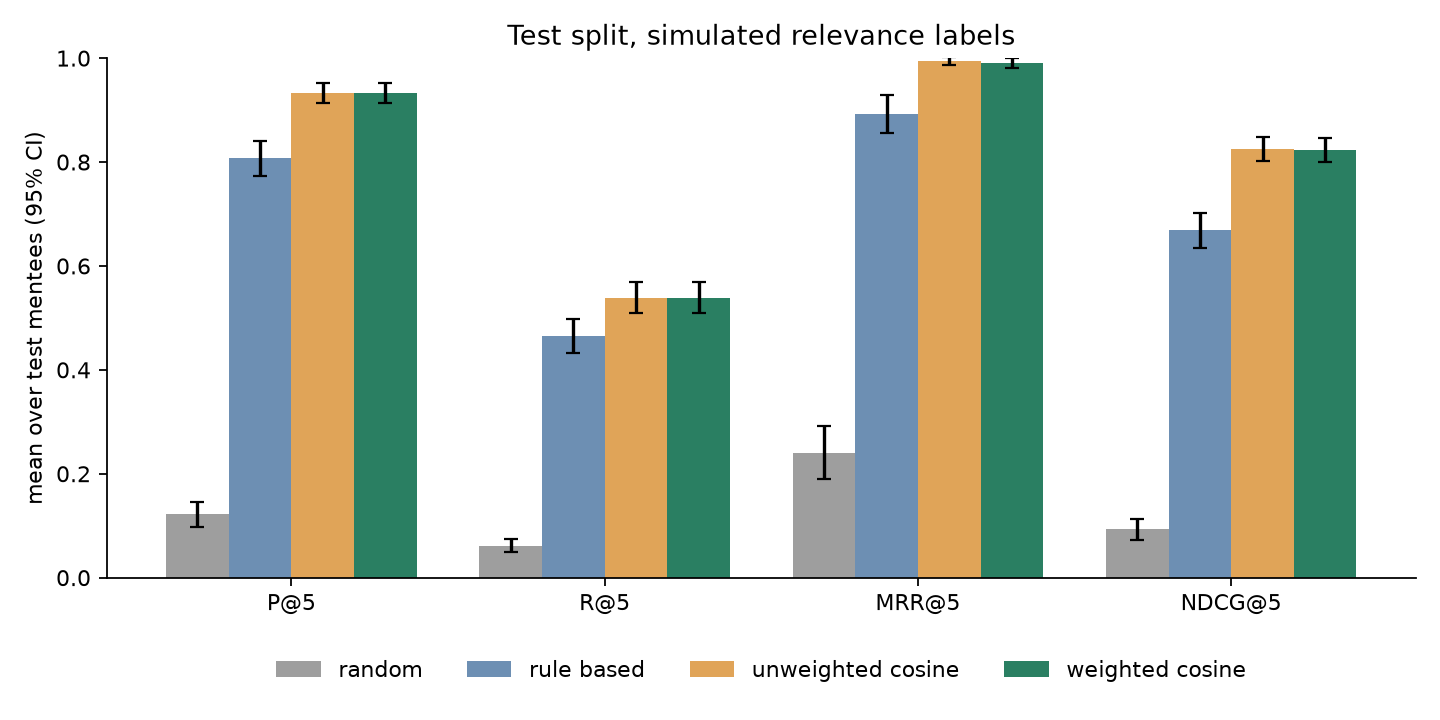

In [6]:
summary = pd.read_csv(paths.REPORTS_DIR / "test_summary.csv")
metric_cols = ["precision@5", "recall@5", "mrr@5", "ndcg@5"]
display(summary[["system", "n_mentees"] + metric_cols].round(3))
display(Image(filename=str(paths.REPORTS_DIR / "figures" / "test_metrics.png")))

In [7]:
tests = pd.read_csv(paths.REPORTS_DIR / "significance_tests.csv")
tests[["compared_with", "mean_difference", "p_value", "n_pairs"]].round(4)

,compared_with,mean_difference,p_value,n_pairs
0,random,0.7306,0.0000,176
1,rule_based,0.1550,0.0000,176
2,skills_only,0.2218,0.0000,176
3,text_only,0.2677,0.0000,176
4,unweighted_cosine,-0.0014,0.7169,176
5,weighted_no_glossary,0.0022,0.6229,176
6,weighted_policy_renormalise,0.0090,0.1798,176
7,weighted_policy_renormalise_content,0.0082,0.0323,176
8,weighted_policy_zero,0.0000,1.0000,176


## 5. Sensitivity analysis

The whole procedure (generate → tune → test) was repeated for 3 seeds under four scenarios: standard data, vocabulary mismatch between mentors and mentees, sparse profiles, and both together.

system,random,rule_based,text_only,skills_only,unweighted_cosine,weighted_cosine
scenario,,,,,,
standard,0.086,0.693,0.580,0.611,0.833,0.834
vocabulary_mismatch,0.082,0.657,0.451,0.594,0.802,0.798
sparse_profiles,0.081,0.564,0.489,0.400,0.735,0.734
hard,0.082,0.548,0.377,0.408,0.708,0.707


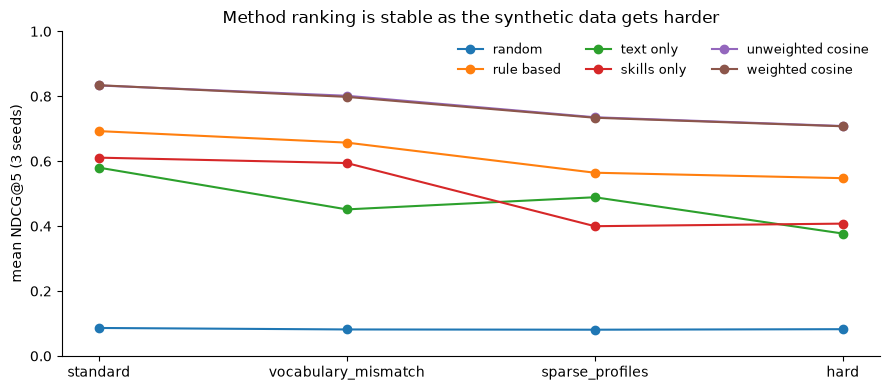

In [8]:
sens = pd.read_csv(paths.REPORTS_DIR / "sensitivity_results.csv")
order = ["standard", "vocabulary_mismatch", "sparse_profiles", "hard"]
systems = ["random", "rule_based", "text_only", "skills_only", "unweighted_cosine", "weighted_cosine"]
pivot = sens.pivot_table(index="scenario", columns="system", values="ndcg@5", aggfunc="mean").loc[order, systems]
display(pivot.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
for system in systems:
    ax.plot(order, pivot[system], marker="o", label=system.replace("_", " "))
ax.set_ylabel("mean NDCG@5 (3 seeds)")
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=3, fontsize=9)
ax.set_title("Method ranking is stable as the synthetic data gets harder")
plt.tight_layout()
plt.show()

**What to take from this (simulated data only):**

* Combining text, skills and specialisation beats the rule-based baseline and either signal alone in every scenario and seed.
* Tuned weights were **never** significantly better than equal weights (equal weights were significantly better in 1 of 12 runs), and the chosen weights changed between seeds. The ranking quality is not sensitive to the exact weights.
* The glossary made little measurable difference. Tags and specialisation compensate for vocabulary mismatch in the text.

## 6. Next step with real people: the expert rating kit

`scripts/build_rating_sheet.py` pools every system's top-5 plus random extras for each mentee into a **blind** sheet: raters don't see which system suggested a mentor. Domain experts rate each pair 0/1/2 using `ratings/RATING_GUIDE.md`. `scripts/score_expert_ratings.py` then reports inter-rater agreement (Cohen's and Fleiss' kappa) and each system's metrics. This gives non-circular ground truth.

The numbers below come from the **demo with simulated raters**, which only shows that the kit runs.

In [9]:
sheet = pd.read_csv(paths.RATINGS_DIR / "rating_sheet_blank.csv")
print(f"Blind sheet: {sheet['mentee_id'].nunique()} mentees, {len(sheet)} pairs")
display(sheet[["pair_id", "mentee_goals", "mentor_role", "mentor_expertise", "rating"]].head(3))
display(Markdown((paths.RATINGS_DIR / "demo" / "expert_results.md").read_text(encoding="utf-8")))

Blind sheet: 30 mentees, 408 pairs


,pair_id,mentee_goals,mentor_role,mentor_expertise,rating
0,P00001,I completed the Short Course in Dangerous Goods Regulations at the Pride Centre. I have 2 years of work experience. ...,Pharma Cargo Coordinator,I work as a Pharma Cargo Coordinator and have been in aviation for 29 years. Comfortable handling fresh produce expo...,NaN
1,P00002,I completed the Short Course in Dangerous Goods Regulations at the Pride Centre. I have 2 years of work experience. ...,Former Cargo Operations Supervisor,"Former Cargo Operations Supervisor with 28 years in aviation, now an independent consultant. Comfortable handling ai...",NaN
2,P00003,I completed the Short Course in Dangerous Goods Regulations at the Pride Centre. I have 2 years of work experience. ...,IT Systems Analyst,IT Systems Analyst at Kenya Airways with 22 years of experience. Solid experience with in-flight first aid. Solid ex...,NaN


# DEMO - simulated raters (not real expert judgements)

Raters: 2; pairs rated by all raters: 408; mentees scored: 30.

Metrics are computed on the pooled pairs only (every system's top-K was judged), so recall is relative to the pool.

## Inter-rater agreement

| Raters | % agreement | Cohen's kappa (quadratic) |
|---|---|---|
| demo_rater_A vs demo_rater_B | 0.79 | 0.84 |

Fleiss' kappa (all raters, unweighted): **0.67**

## Metrics per system (mean ± 95% CI half-width)

| System | precision@5 | recall@5 | mrr@5 | ndcg@5 |
|---|---|---|---|---|
| random | 0.280 ± 0.072 | 0.173 ± 0.043 | 0.497 ± 0.128 | 0.156 ± 0.042 |
| rule_based | 0.867 ± 0.076 | 0.601 ± 0.080 | 0.933 ± 0.078 | 0.774 ± 0.076 |
| unweighted_cosine | 0.947 ± 0.032 | 0.657 ± 0.057 | 1.000 ± 0.000 | 0.862 ± 0.038 |
| weighted_cosine | 0.947 ± 0.032 | 0.657 ± 0.057 | 1.000 ± 0.000 | 0.862 ± 0.037 |

## Wilcoxon signed-rank tests on NDCG@5

| weighted_cosine vs | Mean difference | p-value | Pairs |
|---|---|---|---|
| random | +0.706 | 1.7e-06 | 30 |
| rule_based | +0.088 | 0.067 | 30 |
| unweighted_cosine | -0.000 | 1 | 30 |


## 7. Limitations

* **Synthetic ground truth.** The relevance formula is an assumption, and the text comes from templates. Absolute scores are optimistic; only the comparison under stated assumptions is informative.
* **Lexical matching.** TF-IDF can't recognise paraphrases the glossary doesn't cover (e.g. *fresh produce exports* vs *perishables*).
* **Cold start and self-reporting.** Profile quality depends on what users enter. The taxonomy and glossary are author-defined and need review by Pride Centre / KQ experts.
* **Capacity.** Filters respect each mentor's current capacity, but the ranking doesn't balance load across mentors.
* **Real evaluation still pending.** It needs consent, ethics approval, Kenya Airways permission and expert raters.